In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/dataset.csv")

In [3]:
print(df.shape)
df.head()

(4920, 134)


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis,Unnamed: 133
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN


In [4]:
print("Last 3 columns:", df.columns[-3:].tolist())
print("\nColumns with nulls:")
print(df.isnull().sum().loc[lambda s: s > 0])
print("\nDuplicate rows:", df.duplicated().sum())

Last 3 columns: ['yellow_crust_ooze', 'prognosis', 'Unnamed: 133']

Columns with nulls:
Unnamed: 133    4920
dtype: int64

Duplicate rows: 4616


In [5]:
raw_rows = len(df)

# 1. Drop empty "Unnamed" columns
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

# 2. Tidy column names (fixes typos like 'dischromic _patches')
df.columns = (
    df.columns.str.strip()
    .str.replace(r"\s+", "_", regex=True)
    .str.replace("__", "_")
)

# 3. Drop accidental duplicate columns such as 'fluid_overload.1'
dup_cols = [c for c in df.columns if c.endswith(".1")]
print("Duplicate columns dropped:", dup_cols)
df = df.drop(columns=dup_cols)

# 4. Tidy labels, fill nulls, remove duplicate rows
df["prognosis"] = df["prognosis"].str.strip()
df = df.fillna(0)
df = df.drop_duplicates().reset_index(drop=True)

assert df.columns[-1] == "prognosis"

counts = df["prognosis"].value_counts()
print(f"\nRows: {raw_rows} -> {len(df)}")
print("Symptom columns:", df.shape[1] - 1)
print("Diseases:", df["prognosis"].nunique())
print("Samples per disease -> min:", counts.min(), "| max:", counts.max())

Duplicate columns dropped: ['fluid_overload.1']

Rows: 4920 -> 303
Symptom columns: 131
Diseases: 41
Samples per disease -> min: 5 | max: 10


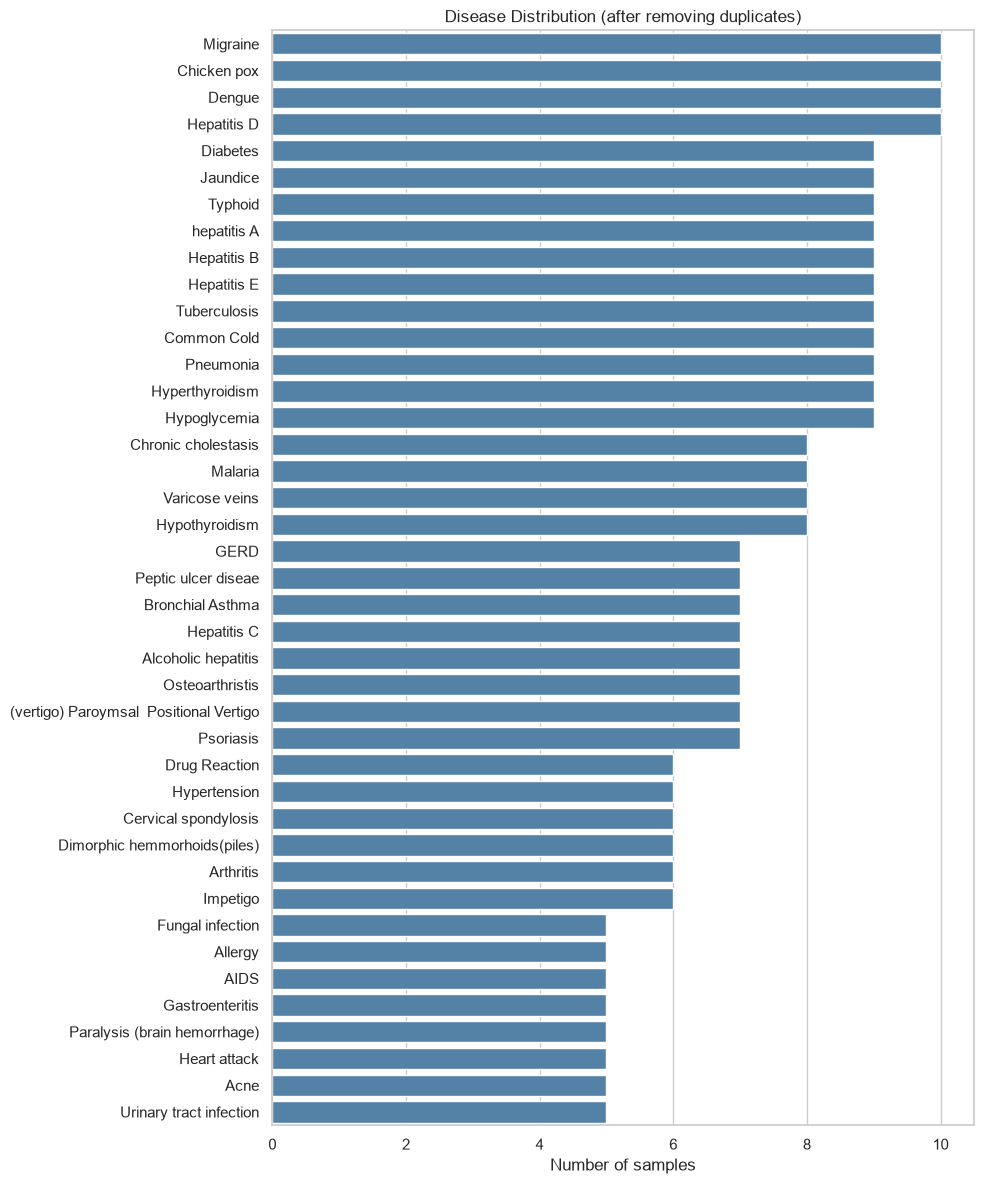

In [6]:
plt.figure(figsize=(10, 12))
sns.barplot(x=counts.values, y=counts.index, color="steelblue")
plt.title("Disease Distribution (after removing duplicates)")
plt.xlabel("Number of samples")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../reports/disease_distribution.png", dpi=150)
plt.show()

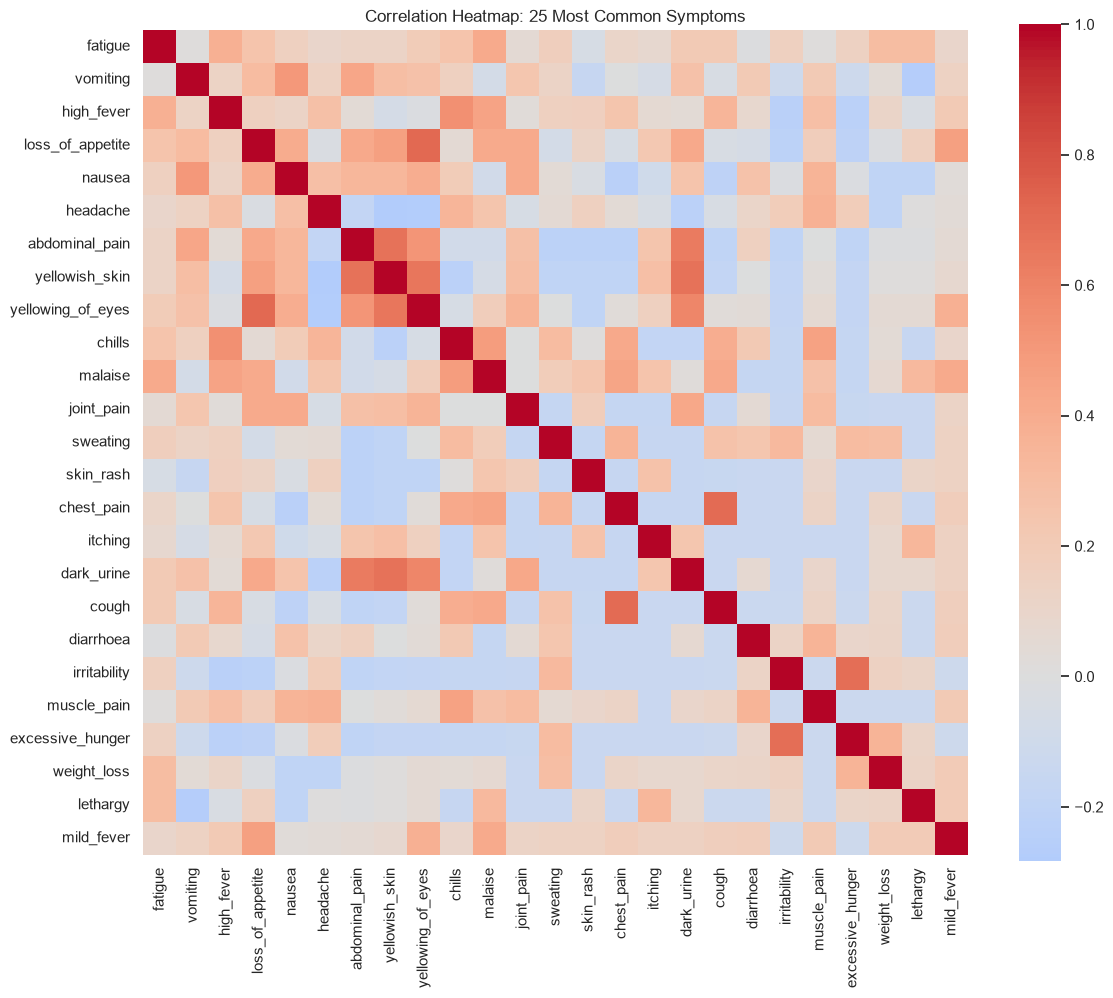

In [7]:
top_symptoms = df.drop(columns="prognosis").sum().nlargest(25).index
corr = df[top_symptoms].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap: 25 Most Common Symptoms")
plt.tight_layout()
plt.savefig("../reports/correlation_heatmap.png", dpi=150)
plt.show()

In [8]:
df.to_csv("../data/cleaned_dataset.csv", index=False)
print("Saved:", df.shape)

Saved: (303, 132)
